## Listes de 9 questions

Quand et comment les clients commandent-ils généralement ?  

Quels produits faut-il mettre en avant le samedi ?  

Quels autres produits les clients commandent-ils fréquemment avec du chocolat ?  

Quels sont les principaux profils de clients : acheteurs nocturnes, acheteurs occasionnels ou accros au  panier ?

Quel article les clients ajoutent-ils en premier à leur panier ?

Quels produits ont le plus de chances d’être commandés à nouveau ?

Les clients commandent-ils en moyenne plus de nourriture pour chats le matin que de nourriture pour chiens le soir ?

Existe-t-il une corrélation entre l’heure de la dernière commande et la probabilité de recommander un produit ?

Peut-on prédire si un produit sera commandé à nouveau par un client lors de sa prochaine visite ?

Importation des modules

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

Ouverture des fichiers 

In [4]:
df_aisles = pd.read_csv("./datasets/aisles.csv")
df_departments = pd.read_csv("./datasets/departments.csv")
df_order_products = pd.read_csv("./datasets/order_products.csv")
df_orders = pd.read_csv("./datasets/orders.csv")
df_products = pd.read_csv("./datasets/products.csv")

Vérifications qu'il n'y a pas de valeurs nul.

In [5]:
display(df_aisles.isnull().sum())
display(df_departments.isnull().sum())
display(df_order_products.isnull().sum())
display(df_orders.isnull().sum())
display(df_products.isnull().sum())

aisle_id    0
aisle       0
dtype: int64

department_id    0
department       0
dtype: int64

order_id               0
product_id           449
add_to_cart_order    446
reordered            449
dtype: int64

order_id                      0
user_id                      31
order_number                 23
order_dow                    22
order_hour_of_day            23
days_since_prior_order    86909
dtype: int64

product_id       0
product_name     0
aisle_id         0
department_id    0
dtype: int64

## Quand et comment les clients commandent-ils généralement ?  

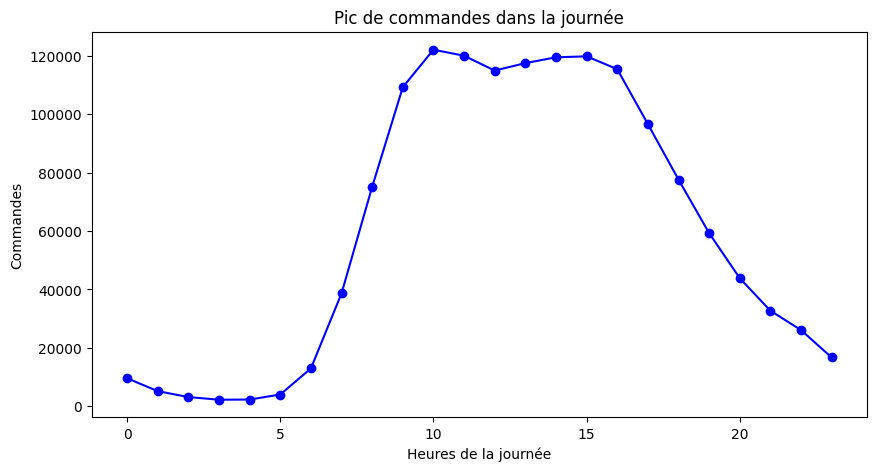

In [6]:
df_orders_hour = df_orders["order_hour_of_day"].value_counts().sort_index()
df_orders_day = df_orders["days_since_prior_order"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.plot(df_orders_hour.index, df_orders_hour.values, marker="o", color="blue")
plt.title("Pic de commandes dans la journée")
plt.xlabel("Heures de la journée")
plt.ylabel("Commandes")
plt.show()

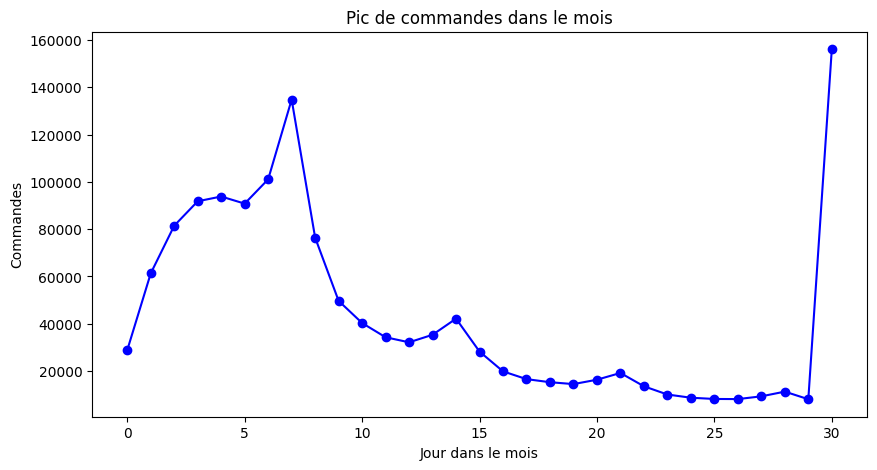

In [7]:
df_orders_hour = df_orders["order_hour_of_day"].value_counts().sort_index()
df_orders_day = df_orders["days_since_prior_order"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.plot(df_orders_day.index, df_orders_day.values, marker="o", color="blue")
plt.title("Pic de commandes dans le mois")
plt.xlabel("Jour dans le mois")
plt.ylabel("Commandes")
plt.show()

Le pic matinal : L'affluence maximale se situe autour de 10h du matin. Les clients ont donc tendance à organiser leurs courses en ligne en milieu de matinée plutôt que le soir.

La routine hebdomadaire : On observe des rebonds de commandes très nets tous les 7, 14 et 21 jours. Cela met en lumière une routine bien ancrée chez les familles, qui effectuent leurs achats de manière très régulière, semaine après semaine.

Le grand ravitaillement mensuel : Le pic le plus important se trouve à 30 jours. Il correspond aux clients qui font un gros "plein" une fois par mois (souvent après la paie), mais il représente aussi un plafond technique de la base de données qui regroupe toutes les commandes espacées de 30 jours et plus.

## Quels produits faut-il mettre en avant le samedi ?  

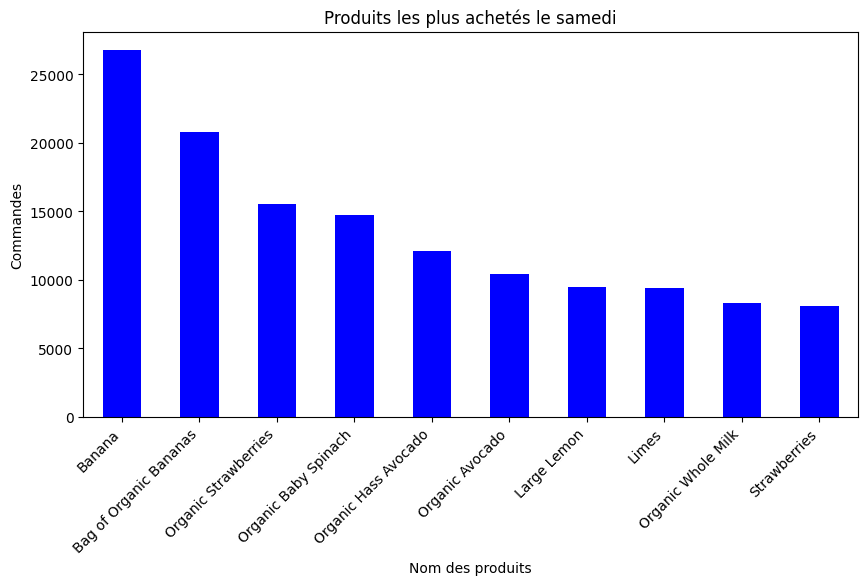

In [16]:
df_orders_saturday = df_orders[df_orders["order_dow"] == 6]
df_sat_prod = pd.merge(df_orders_saturday, df_order_products, on="order_id")
df_final = pd.merge(df_sat_prod, df_products, on="product_id")
top_10_sat = df_final["product_name"].value_counts().head(10)

df_orders_sat = df_sat_prod["product_id"].value_counts().sort_index()
plt.figure(figsize=(10, 5))
top_10_sat.plot(kind="bar", color="blue")
plt.xticks(rotation=45, ha="right")
plt.title("Produits les plus achetés le samedi")
plt.xlabel("Nom des produits")
plt.ylabel("Commandes")
plt.show()

`Au vu des données, nous recommandons de mettre fortement en avant les bananes le samedi, car il y a plus de 25 000 commandes pour ce produit ce jour-là.`

## Quels autres produits les clients commandent-ils fréquemment avec du chocolat ?  


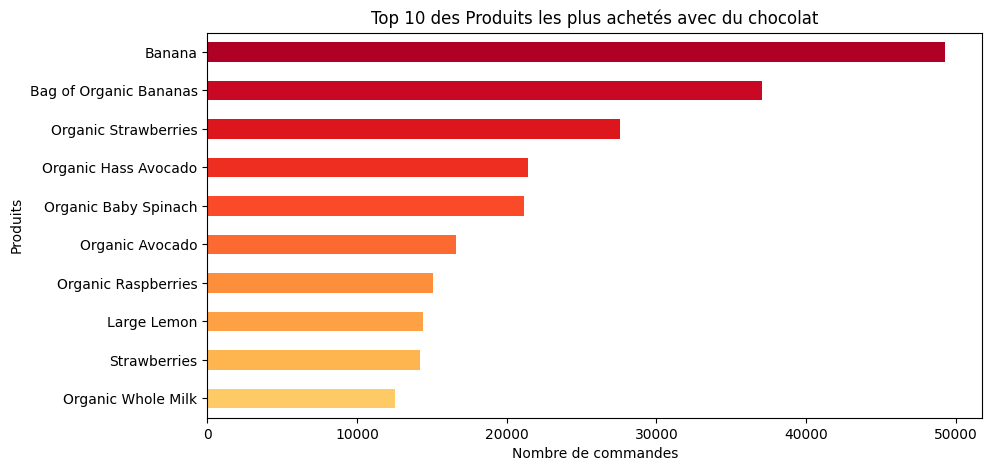

In [41]:
df_chocolat = df_products[df_products["product_name"].str.contains("Chocolate", na=False)]
df_chocolat_panier = pd.merge(df_chocolat, df_order_products, on="product_id")
df_chocolat_final = df_chocolat_panier["order_id"]
df_product_article = df_order_products[df_order_products["order_id"].isin(df_chocolat_final)]
df_nom_finaux = pd.merge(df_product_article, df_products, on="product_id")

produit_avec_chocolat = df_nom_finaux["product_name"].value_counts().head(10)

couleurs = plt.cm.YlOrRd(np.linspace(0.9, 0.3, 10))

plt.figure(figsize=(10, 5))
produit_avec_chocolat.plot(kind="barh", color=couleurs)
plt.title("Top 10 des Produits les plus achetés avec du chocolat")
plt.xlabel("Nombre de commandes")
plt.ylabel("Produits")
plt.gca().invert_yaxis()
plt.show()

On en conclut donc que, même en achetant du chocolat, les bananes dominent largement les paniers des clients.

En conclusion, même lors d'un achat plaisir comme le chocolat, les bananes et les produits frais continuent de dominer largement le panier des clients.